<a href="https://colab.research.google.com/github/MrNamu22/India-Life-Insurance-Pricing/blob/main/india_life_insurance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/yuiseki/un-wpp/resolve/main/raw/wpp2024/WPP2024_Life_Table_Complete_Medium_Both_1950-2023.csv.gz"

columns = ["Location", "Time", "AgeGrpStart", "qx", "lx", "ex"]
raw = pd.read_csv(url, usecols=columns)

print(raw.shape)
raw.head()

(4148070, 6)


,Location,Time,AgeGrpStart,qx,lx,ex
0,ADB region: Central and West Asia,1950,0,0.207083,100000.000,38.6085
1,ADB region: Central and West Asia,1950,1,0.076109,79291.658,47.6070
2,ADB region: Central and West Asia,1950,2,0.042543,73256.879,50.4876
3,ADB region: Central and West Asia,1950,3,0.024707,70140.310,51.7087
4,ADB region: Central and West Asia,1950,4,0.015251,68407.382,52.0060


In [2]:
india = raw[(raw["Location"] == "India") & (raw["Time"].isin([1990, 2023]))]

print(india.shape)
print(india["AgeGrpStart"].min(), "to", india["AgeGrpStart"].max())

india.to_csv("india_life_table_1990_2023.csv", index=False)

india[india["AgeGrpStart"] == 30]

(202, 6)
0 to 100


,Location,Time,AgeGrpStart,qx,lx,ex
2799346,India,1990,30,0.002965,82251.083,40.0451
2802679,India,2023,30,0.001240,95609.867,44.9477


In [3]:
def build_life_table(year):
    t = india[india["Time"] == year].sort_values("AgeGrpStart")
    q = t["qx"].values
    p = 1 - q

    l = [100000.0]
    for x in range(100):
        l.append(l[x] * p[x])

    table = pd.DataFrame({
        "age": t["AgeGrpStart"].values,
        "qx": q,
        "px": p,
        "lx": l,
        "lx_UN": t["lx"].values,
    })
    return table

lt1990 = build_life_table(1990)
lt2023 = build_life_table(2023)

print("Largest difference from UN, 1990:", abs(lt1990["lx"] - lt1990["lx_UN"]).max())
print("Largest difference from UN, 2023:", abs(lt2023["lx"] - lt2023["lx_UN"]).max())
lt2023.loc[28:32]

Largest difference from UN, 1990: 0.0035779440659098327
Largest difference from UN, 2023: 0.0020095668587600812


,age,qx,px,lx,lx_UN
28,28,0.001166,0.998834,95835.983449,95835.982
29,29,0.001195,0.998805,95724.261693,95724.260
30,30,0.001240,0.998760,95609.868329,95609.867
31,31,0.001307,0.998693,95491.307312,95491.306
32,32,0.001394,0.998606,95366.490624,95366.489


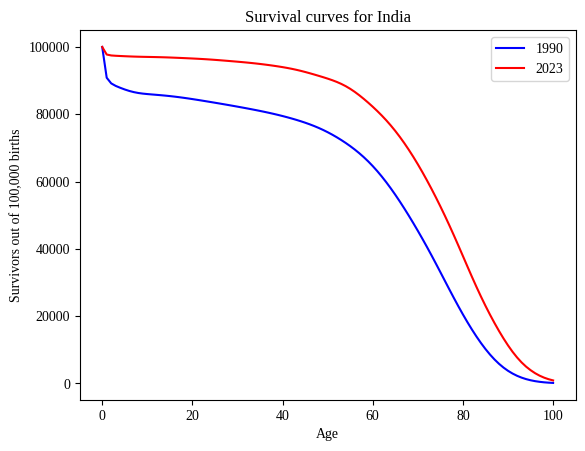

Reach age 60, 1990: 64588
Reach age 60, 2023: 82220


In [4]:
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]

plt.plot(lt1990["age"], lt1990["lx"], "b", label="1990")
plt.plot(lt2023["age"], lt2023["lx"], "r", label="2023")
plt.title("Survival curves for India")
plt.xlabel("Age")
plt.ylabel("Survivors out of 100,000 births")
plt.legend()
plt.savefig("survival_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Reach age 60, 1990:", round(lt1990["lx"][60]))
print("Reach age 60, 2023:", round(lt2023["lx"][60]))

In [5]:
S = 5_000_000
x = 30
n = 20
i = 0.06
v = 1 / (1 + i)

l = lt2023["lx"].values

epv_benefit = 0
for k in range(n):
    prob_die = (l[x + k] - l[x + k + 1]) / l[x]
    epv_benefit = epv_benefit + S * v ** (k + 1) * prob_die

print("Chance of dying within 20 years:", (l[x] - l[x + n]) / l[x])
print("Discount factor v:", v)
print("EPV of benefits (rupees):", round(epv_benefit))

Chance of dying within 20 years: 0.052619175622923106
Discount factor v: 0.9433962264150942
EPV of benefits (rupees): 131377


In [6]:
def premium(table, x, n, i, S):
    l = table["lx"].values
    v = 1 / (1 + i)

    epv_benefit = 0
    annuity = 0
    for k in range(n):
        epv_benefit = epv_benefit + S * v ** (k + 1) * (l[x + k] - l[x + k + 1]) / l[x]
        annuity = annuity + v ** k * l[x + k] / l[x]

    return epv_benefit / annuity

P2023 = premium(lt2023, 30, 20, 0.06, 5_000_000)
P1990 = premium(lt1990, 30, 20, 0.06, 5_000_000)

print("Fair annual premium, 2023 mortality:", round(P2023))
print("Fair annual premium, 1990 mortality:", round(P1990))
print("Ratio 1990 / 2023:", round(P1990 / P2023, 2))

Fair annual premium, 2023 mortality: 10963
Fair annual premium, 1990 mortality: 20193
Ratio 1990 / 2023: 1.84


2 %   1990: 22571   2023: 12527
3 %   1990: 21935   2023: 12111
4 %   1990: 21326   2023: 11711
5 %   1990: 20746   2023: 11329
6 %   1990: 20193   2023: 10963
7 %   1990: 19666   2023: 10614
8 %   1990: 19167   2023: 10282
9 %   1990: 18692   2023: 9967
10 %   1990: 18243   2023: 9667


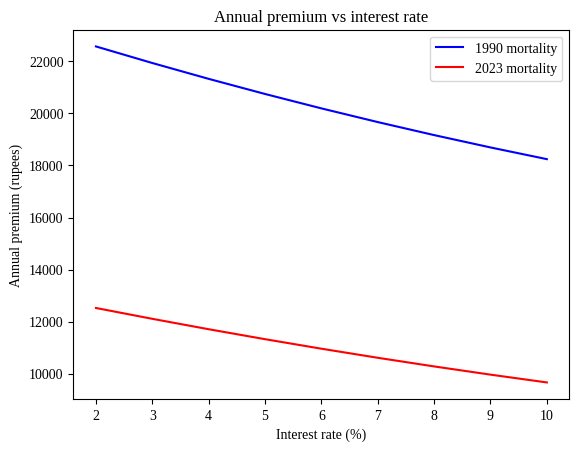

In [7]:
rates = np.arange(0.02, 0.105, 0.01)

prem_2023 = []
prem_1990 = []
for rate in rates:
    prem_2023.append(premium(lt2023, 30, 20, rate, 5_000_000))
    prem_1990.append(premium(lt1990, 30, 20, rate, 5_000_000))

for rate, a, b in zip(rates, prem_1990, prem_2023):
    print(round(rate * 100), "%   1990:", round(a), "  2023:", round(b))

plt.plot(rates * 100, prem_1990, "b", label="1990 mortality")
plt.plot(rates * 100, prem_2023, "r", label="2023 mortality")
plt.title("Annual premium vs interest rate")
plt.xlabel("Interest rate (%)")
plt.ylabel("Annual premium (rupees)")
plt.legend()
plt.savefig("premium_vs_interest.png", dpi=150, bbox_inches="tight")
plt.show()

Age 20   1990: 13773   2023: 5680
Age 30   1990: 20193   2023: 10963
Age 40   1990: 40404   2023: 25740
Age 50   1990: 92373   2023: 62174
Age 60   1990: 199219   2023: 139462


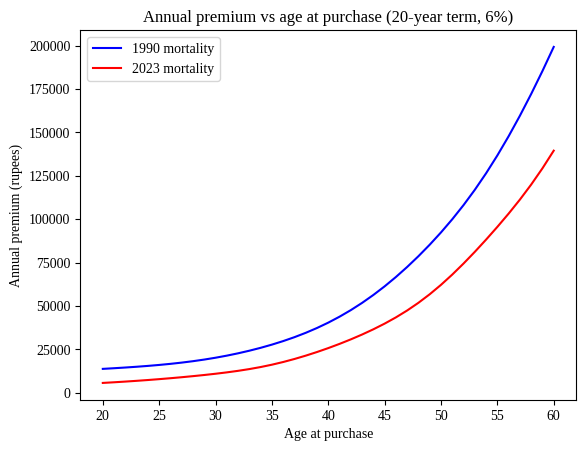

In [8]:
ages = np.arange(20, 61)

age_2023 = []
age_1990 = []
for age in ages:
    age_2023.append(premium(lt2023, age, 20, 0.06, 5_000_000))
    age_1990.append(premium(lt1990, age, 20, 0.06, 5_000_000))

for age in [20, 30, 40, 50, 60]:
    print("Age", age, "  1990:", round(age_1990[age - 20]), "  2023:", round(age_2023[age - 20]))

plt.plot(ages, age_1990, "b", label="1990 mortality")
plt.plot(ages, age_2023, "r", label="2023 mortality")
plt.title("Annual premium vs age at purchase (20-year term, 6%)")
plt.xlabel("Age at purchase")
plt.ylabel("Annual premium (rupees)")
plt.legend()
plt.savefig("premium_vs_age.png", dpi=150, bbox_inches="tight")
plt.show()